# Dữ liệu SoccerBench

In [1]:
import sys, time, tempfile
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.config import SOCCERBENCH_ROOT, TASK_IDS, TASK_META
from sva.data import (CATEGORIES, audit_all, build_index, build_splits, load_clean, load_raw,
                      parse_option_keys, verify_no_leakage)
from sva.perception import PerceptionCache, build_encoder, letterbox, probe, sample_frames

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b4ae"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})
pd.set_option("display.max_colwidth", 80)

## 1. Dữ liệu thô

In [2]:
raw = {t: load_raw(t) for t in TASK_IDS}

rows = []
for t, recs in raw.items():
    n_clips = Counter(len(r["materials"]) for r in recs)
    files = {m for r in recs for m in r["materials"]}
    rows.append({"task": t, "paper": TASK_META[t]["paper_id"], "tên": TASK_META[t]["name"],
                 "số mẫu": len(recs), "clip/mẫu": dict(sorted(n_clips.items())), "số file video": len(files)})
overview = pd.DataFrame(rows).set_index("task")
overview

,paper,tên,số mẫu,clip/mẫu,số file video
task,,,,,
q8,Q7,Camera Status Switching,400,{1: 400},400
q9,Q8,Replay Grounding,400,{5: 400},1989
q10,Q9,Action Classification,1000,{1: 1000},1000
q11,Q10,Commentary Generation,1000,{1: 1000},1000
q13,Q12,Jersey Color Relevant QA,700,{1: 700},700
q14,Q13,Multi-view Foul Recognition,300,"{2: 219, 3: 71, 4: 10}",434


In [3]:
for t in TASK_IDS:
    r = raw[t][1]
    print(f"--- {t} ({TASK_META[t]['paper_id']}) ---")
    print("Q:", r["Q"])
    for k in parse_option_keys(r):
        print(f"  {k}: {str(r[k])[:90]}")
    print("closeA:", r["closeA"], "| openA:", str(r["openA"])[:90], "\n")

--- q8 (Q7) ---
Q: What kind of camera transitions are used in the video?
  O1: From Other to Other.
  O2: From Main camera center to Close-up corner.
  O3: From Spider camera to Public.
  O4: From Public to Main camera left.
closeA: O3 | openA: From Spider camera to Public. 

--- q9 (Q8) ---
Q: The first video clip is a replay. From the remaining four clips, please choose which one is being replayed.
  O1: The 1st one.
  O2: The 2nd one.
  O3: The 3rd one.
  O4: The 4th one.
closeA: O1 | openA: ['/remote-home/jiayuanrao/projects/MatchRAG/final_benchmark/materials/q9/action/europe_uef 

--- q10 (Q9) ---
Q: What kind of football event is depicted in this video?
  O1: substitution
  O2: lead to corner
  O3: off side
  O4: foul lead to penalty
closeA: O1 | openA: substitution 

--- q11 (Q10) ---
Q: Provide a commentary text for this football video.
  O1: [PLAYER] ([TEAM]) leaps high near the penalty spot and gets a header in from the free kick
  O2: [PLAYER] ([TEAM]) brings his opponent d

## 2. Các vấn đề của dữ liệu

### 2.1 Số phương án không cố định (q14)

In [4]:
opt = pd.DataFrame({t: Counter(len(parse_option_keys(r)) for r in raw[t]) for t in TASK_IDS}).T.fillna(0).astype(int)
opt = opt[sorted(opt.columns)]
opt.columns = [f"{c} option" for c in opt.columns]
opt

,2 option,3 option,4 option
q8,0,0,400
q9,0,0,400
q10,0,0,1000
q11,0,0,1000
q13,0,0,700
q14,174,53,73


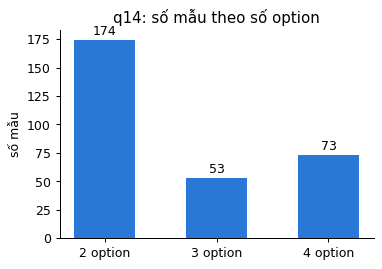

In [5]:
c = opt.loc["q14"]
fig, ax = plt.subplots(figsize=(4.5, 3))
bars = ax.bar(c.index, c.values, color=BLUE, width=0.55)
ax.bar_label(bars, padding=2)
ax.set_title("q14: số mẫu theo số option")
ax.set_ylabel("số mẫu")
plt.show()

In [6]:
# phuong an khong lien tuc: co O1, O3 ma khong co O2
def is_contiguous(keys):
    return [int(k[1:]) for k in keys] == list(range(1, len(keys) + 1))

gaps = [(i, parse_option_keys(r)) for i, r in enumerate(raw["q14"]) if not is_contiguous(parse_option_keys(r))]
print(len(gaps), "mẫu q14 có option không liên tục")
print(Counter(tuple(k) for _, k in gaps))

i = gaps[0][0]
{k: raw["q14"][i][k] for k in ["Q", "closeA"] + gaps[0][1]}

18 mẫu q14 có option không liên tục
Counter({('O1', 'O3'): 10, ('O2', 'O3'): 8})


{'Q': 'The foul has been recorded from 3 different perspectives: Main camera center lens at 1.0x speed, Main behind the goal lens at 1.4x speed, Close-up player or field referee lens at 1.8x speed. Did this foul involve a handball?',
 'closeA': 'O1',
 'O1': 'No',
 'O3': 'Yes'}

### 2.2 Đáp án đóng (closeA) không khớp đáp án mở (openA)

In [7]:
reports = {r.task_id: r for r in audit_all()}
audit = pd.DataFrame({t: r.counts for t, r in reports.items()}).T.reindex(columns=CATEGORIES).fillna(0).astype(int)
audit

,OK,OK_NONCONTIGUOUS,RECOVERABLE,UNRECOVERABLE,INDEX_ERROR,OPENA_EMPTY,OPENA_IS_LIST,NO_MATCH
q8,400,0,0,0,0,0,0,0
q9,0,0,0,0,0,0,400,0
q10,1000,0,0,0,0,0,0,0
q11,1000,0,0,0,0,0,0,0
q13,695,0,0,0,1,4,0,0
q14,251,18,7,24,0,0,0,0


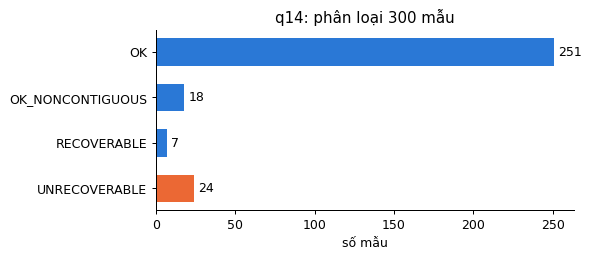

In [8]:
c = audit.loc["q14"]
c = c[c > 0]
fig, ax = plt.subplots(figsize=(6, 2.6))
colors = [ORANGE if k == "UNRECOVERABLE" else BLUE for k in c.index]
bars = ax.barh(c.index[::-1], c.values[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, padding=3)
ax.set_title("q14: phân loại 300 mẫu")
ax.set_xlabel("số mẫu")
plt.show()

In [9]:
def problem_table(task, categories):
    rows = []
    for rec in reports[task].records:
        if rec.category not in categories:
            continue
        r = raw[task][rec.index]
        rows.append({"index": rec.index, "loại": rec.category, "openA": r["openA"], "closeA": r["closeA"],
                     "options": {k: r[k] for k in parse_option_keys(r)}, "sửa thành": rec.fixed})
    return pd.DataFrame(rows).set_index("index")

# sua duoc: openA khop voi 1 option khac
pd.concat([problem_table("q14", ["RECOVERABLE"]), problem_table("q13", ["INDEX_ERROR"])], keys=["q14", "q13"])

loại              openA closeA  \
    index                                          
q14 41     RECOVERABLE  Standing tackling     O6   
    70     RECOVERABLE  Standing tackling     O8   
    86     RECOVERABLE  Standing tackling     O9   
    148    RECOVERABLE  Standing tackling     O7   
    203    RECOVERABLE  Standing tackling     O9   
    208    RECOVERABLE  Standing tackling     O5   
    280    RECOVERABLE  Standing tackling     O6   
q13 163    INDEX_ERROR                red     O3   

                                                                                 options  \
    index                                                                                  
q14 41        {'O1': 'Elbowing', 'O2': 'Holding', 'O3': 'Pushing', 'O4': 'St. tackling'}   
    70         {'O1': 'Elbowing', 'O2': 'St. tackling', 'O3': 'Challenge', 'O4': 'Dive'}   
    86        {'O1': 'Holding', 'O2': 'St. tackling', 'O3': 'Tackling', 'O4': 'Pushing'}   
    148     {'O1': 'Pushing', 'O2': 'High leg', 'O3': 'Challenge', 'O4': 'St. tackling'}   
    203      {'O1': 'Pushing', 'O2': 'St. tackling', 'O3': 'Elbowing', 'O4': 'High leg'}   
    208    {'O1': 'Tackling', 'O2': 'High leg', 'O3': 'St. tackling', 'O4': 'Challenge'}   
    280      {'O1': 'High leg', 'O2': 'Tackling', 'O3': 'St. tackling', 'O4': 'Holding'}   
q13 163                       {'O1': 'white', 'O2': 'red', 'O3': 'blue', 'O4': 'silver'}   

          sửa thành  
    index            
q14 41           O4  
    70           O2  
    86           O2  
    148          O4  
    203          O2  
    208          O3  
    280          O3  
q13 163          O2

In [10]:
# khong sua duoc: openA khong khop option nao -> bo
bad = problem_table("q14", ["UNRECOVERABLE"])
print(len(bad), "mẫu")
bad.head(8)

24 mẫu


,loại,openA,closeA,options,sửa thành
index,,,,,
6,UNRECOVERABLE,Tackling,O8,"{'O1': 'Challenge', 'O2': 'St. tackling', 'O3': 'High leg', 'O4': 'Pushing'}",None
8,UNRECOVERABLE,Challenge,O8,"{'O1': 'Holding', 'O2': 'Tackling', 'O3': 'Dive', 'O4': 'Pushing'}",None
45,UNRECOVERABLE,Standing tackling,O9,"{'O1': 'Pushing', 'O2': 'Tackling', 'O3': 'Holding', 'O4': 'Elbowing'}",None
46,UNRECOVERABLE,Elbowing,O6,"{'O1': 'High leg', 'O2': 'Tackling', 'O3': 'Holding', 'O4': 'Challenge'}",None
53,UNRECOVERABLE,High leg,O7,"{'O1': 'Challenge', 'O2': 'Holding', 'O3': 'Tackling', 'O4': 'Pushing'}",None
72,UNRECOVERABLE,Challenge,O5,"{'O1': 'Pushing', 'O2': 'High leg', 'O3': 'Tackling', 'O4': 'Dive'}",None
77,UNRECOVERABLE,No card,O5,"{'O1': 'Yellow card or red card', 'O2': 'Yellow card', 'O3': 'Red card', 'O4...",None
83,UNRECOVERABLE,No card,O5,"{'O1': 'Yellow card', 'O2': 'No card or yellow card', 'O3': 'Red card', 'O4'...",None


In [11]:
problem_table("q13", ["OPENA_EMPTY"])[["openA", "closeA", "options"]]

,openA,closeA,options
index,,,
225,,O2,"{'O1': 'blue', 'O2': 'purple', 'O3': 'white', 'O4': 'turquoise'}"
297,,O1,"{'O1': 'purple', 'O2': 'blue', 'O3': 'teal', 'O4': 'white'}"
484,,O1,"{'O1': 'brown', 'O2': 'black', 'O3': 'violet', 'O4': 'red'}"
688,,O2,"{'O1': 'blue', 'O2': 'navy', 'O3': 'white', 'O4': 'lavender'}"


### 2.3 openA của q9 là đường dẫn trên máy tác giả

In [12]:
r = raw["q9"][0]
print("openA  :", r["openA"][0])
print("closeA :", r["closeA"])
for i, m in enumerate(r["materials"][1:], 1):
    print(f"  ứng viên {i}: {Path(m).name}")

openA  : /remote-home/jiayuanrao/projects/MatchRAG/final_benchmark/materials/q9/action/france_ligue-1/2016-2017/2016-08-28 - 21-45 Monaco 3 - 1 Paris SG/action/2_6_37.mp4
closeA : O3
  ứng viên 1: 1_27_23.mp4
  ứng viên 2: 2_42_56.mp4
  ứng viên 3: 2_6_37.mp4
  ứng viên 4: 1_3_41.mp4


### 2.4 Video: fps, độ dài, kích thước

In [13]:
rows = []
for t in TASK_IDS:
    for r in raw[t]:
        m = probe(SOCCERBENCH_ROOT / r["materials"][0])
        rows.append({"task": t, "fps": m.fps, "duration": m.duration, "w": m.width, "h": m.height})
video = pd.DataFrame(rows)
video["hướng"] = np.where(video.w > video.h, "ngang", "dọc")

video.groupby("task", sort=False).agg(fps_min=("fps", "min"), fps_max=("fps", "max"),
                                      dur_min=("duration", "min"), dur_tb=("duration", "mean"),
                                      dur_max=("duration", "max")).round(2)

,fps_min,fps_max,dur_min,dur_tb,dur_max
task,,,,,
q8,17.43,25.0,5.96,7.49,9.76
q9,16.70,25.0,10.00,13.03,23.00
q10,25.00,25.0,29.80,30.01,30.12
q11,25.00,25.0,29.92,30.01,30.12
q13,25.00,25.0,30.00,30.04,30.16
q14,25.00,25.0,5.04,5.04,5.04


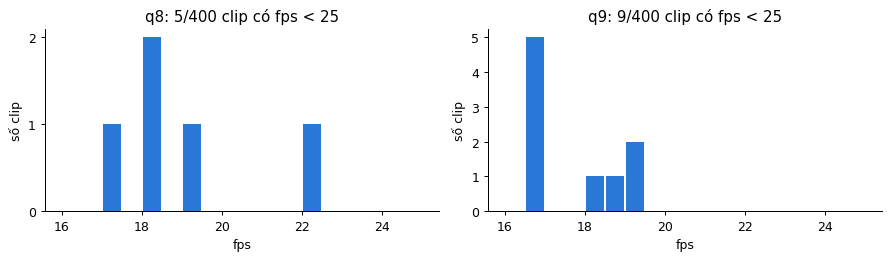

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

low = video[video.fps < 24.9]
for ax, t in zip(axes, ["q8", "q9"]):
    d = low[low.task == t].fps
    ax.hist(d, bins=np.arange(16, 25.5, 0.5), color=BLUE, rwidth=0.9)
    ax.set_title(f"{t}: {len(d)}/{(video.task == t).sum()} clip có fps < 25")
    ax.set_xlabel("fps")
    ax.set_ylabel("số clip")
    ax.yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

hướng,ngang,dọc
task,,
q8,400,0
q9,400,0
q10,800,200
q11,700,300
q13,0,700
q14,300,0


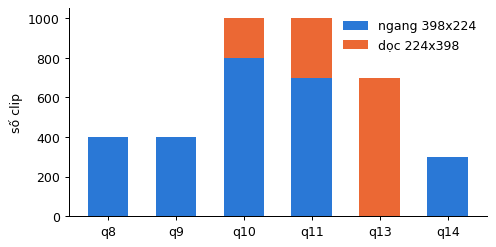

In [15]:
ori = video.groupby(["task", "hướng"], sort=False).size().unstack(fill_value=0).reindex(TASK_IDS)[["ngang", "dọc"]]
display(ori)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(ori.index, ori["ngang"], color=BLUE, width=0.6, label="ngang 398x224")
ax.bar(ori.index, ori["dọc"], bottom=ori["ngang"], color=ORANGE, width=0.6, label="dọc 224x398")
ax.set_ylabel("số clip")
ax.legend(frameon=False)
plt.show()

### 2.5 q14: nhiều câu hỏi dùng chung một bộ clip

300 mẫu / 186 pha phạm lỗi; 691 lượt dùng clip / 434 file


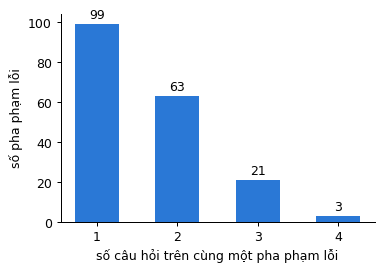

In [16]:
action = Counter(Path(r["materials"][0]).parent.name for r in raw["q14"])
per_action = Counter(action.values())
declared = sum(len(r["materials"]) for r in raw["q14"])
files = len({m for r in raw["q14"] for m in r["materials"]})
print(f"{len(raw['q14'])} mẫu / {len(action)} pha phạm lỗi; {declared} lượt dùng clip / {files} file")

fig, ax = plt.subplots(figsize=(4.5, 3))
xs = sorted(per_action)
bars = ax.bar([str(x) for x in xs], [per_action[x] for x in xs], color=BLUE, width=0.55)
ax.bar_label(bars, padding=2)
ax.set_xlabel("số câu hỏi trên cùng một pha phạm lỗi")
ax.set_ylabel("số pha phạm lỗi")
plt.show()

## 3. Sau khi làm sạch

In [17]:
clean = {t: load_clean(t) for t in TASK_IDS}

summary = pd.DataFrame({
    "trước": {t: len(raw[t]) for t in TASK_IDS},
    "sau": {t: len(clean[t]) for t in TASK_IDS},
    "bỏ": {t: len(raw[t]) - len(clean[t]) for t in TASK_IDS},
    "sửa closeA": {t: sum(s.cleaning_note == "closeA_fixed" for s in clean[t]) for t in TASK_IDS},
    "gắn cờ openA rỗng": {t: sum(s.cleaning_note == "openA_empty" for s in clean[t]) for t in TASK_IDS},
})
summary

,trước,sau,bỏ,sửa closeA,gắn cờ openA rỗng
q8,400,400,0,0,0
q9,400,400,0,0,0
q10,1000,1000,0,0,0
q11,1000,1000,0,0,0
q13,700,700,0,1,4
q14,300,276,24,7,0


In [18]:
rows = []
for t in ["q13", "q14"]:
    for s in clean[t]:
        if s.cleaning_note == "closeA_fixed":
            rows.append({"task": t, "index": s.index, "openA": s.open_answer, "closeA cũ": raw[t][s.index]["closeA"],
                         "gold_key": s.gold_key, "text": s.option_texts[s.gold_key]})
pd.DataFrame(rows)

,task,index,openA,closeA cũ,gold_key,text
0,q13,163,red,O3,O2,red
1,q14,41,Standing tackling,O6,O4,St. tackling
2,q14,70,Standing tackling,O8,O2,St. tackling
3,q14,86,Standing tackling,O9,O2,St. tackling
4,q14,148,Standing tackling,O7,O4,St. tackling
5,q14,203,Standing tackling,O9,O2,St. tackling
6,q14,208,Standing tackling,O5,O3,St. tackling
7,q14,280,Standing tackling,O6,O3,St. tackling


In [19]:
# q9: gold suy ra tu ten file, phai trung closeA
s = clean["q9"][0]
print(s.open_answer, "->", s.gold_key, "|", s.meta["match_name"])
assert all(x.gold_key in x.option_keys for t in TASK_IDS for x in clean[t])

2_6_37.mp4 -> O3 | 2016-08-28 - 21-45 Monaco 3 - 1 Paris SG


### 3.1 Chia dev / test

In [20]:
splits = build_splits()

rows = []
for t in TASK_IDS:
    sp = splits[t]
    rows.append({"task": t, "số nhóm": len(build_index(clean[t])), "dev": len(sp["dev"]), "test": len(sp["test"]),
                 "không rò rỉ": verify_no_leakage(clean[t], sp)})
pd.DataFrame(rows).set_index("task")

,số nhóm,dev,test,không rò rỉ
task,,,,
q8,400,120,280,True
q9,275,120,280,True
q10,1000,300,700,True
q11,1000,300,700,True
q13,700,210,490,True
q14,176,84,192,True


## 4. Lấy frame

What kind of camera transitions are used in the video? -> From Spider camera to Public.


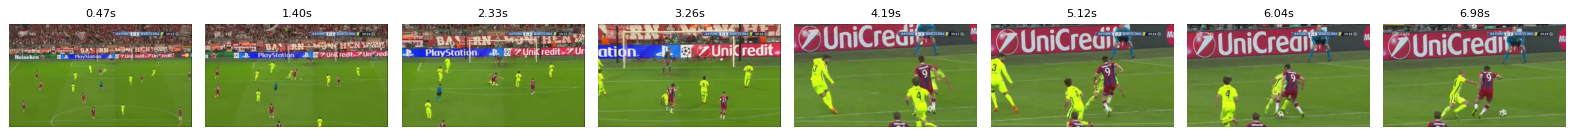

In [21]:
def show_frames(frames, titles, figsize=None, suptitle=None):
    n = len(frames)
    fig, axes = plt.subplots(1, n, figsize=figsize or (2.2 * n, 2))
    for ax, f, title in zip(np.atleast_1d(axes), frames, titles):
        ax.imshow(f)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()

path = clean["q8"][1].materials[0]
frames, ts = sample_frames(path, 8)
s = clean["q8"][1]
print(s.question, "->", s.option_texts[s.gold_key])
show_frames(frames, [f"{t:.2f}s" for t in ts])

In [22]:
# 2 clip dai bang nhau nhung fps khac nhau
q8 = SOCCERBENCH_ROOT / "materials" / "q8"
a = probe(q8 / "england_epl/2015-2016/2015-11-29 - 15-00 Tottenham 0 - 0 Chelsea/1_2656.mp4")
b = probe(q8 / "italy_serie-a/2016-2017/2016-08-28 - 21-45 Cagliari 2 - 2 AS Roma/1_887.mp4")

rows = []
for name, m in [("A", a), ("B", b)]:
    _, ts = sample_frames(m.path, 8)
    idx = np.arange(8) * 15   # neu cu 15 frame lay 1
    rows.append({"clip": name, "fps": round(m.fps, 2), "duration": round(m.duration, 2), "n_frames": m.n_frames,
                 "theo timestamp (s)": np.round(ts, 2), "cứ 15 frame lấy 1 (s)": np.round(idx / m.fps, 2)})
pd.DataFrame(rows).set_index("clip")

,fps,duration,n_frames,theo timestamp (s),cứ 15 frame lấy 1 (s)
clip,,,,,
A,25.00,6.72,168,"[0.42, 1.26, 2.1, 2.94, 3.78, 4.62, 5.46, 6.3]","[0.0, 0.6, 1.2, 1.8, 2.4, 3.0, 3.6, 4.2]"
B,18.01,6.72,121,"[0.42, 1.26, 2.1, 2.94, 3.78, 4.62, 5.46, 6.3]","[0.0, 0.83, 1.67, 2.5, 3.33, 4.17, 5.0, 5.83]"


### 4.1 Clip 224x398 là hình ngang bị bóp

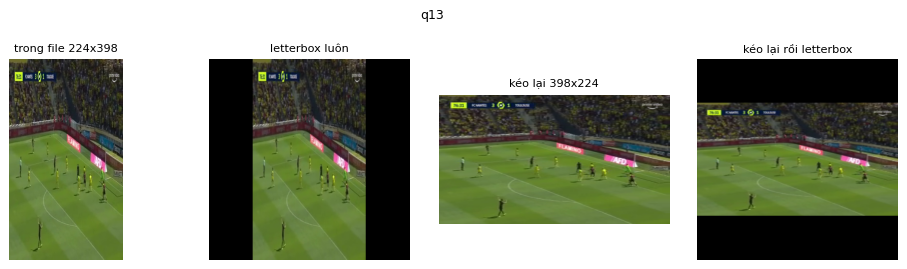

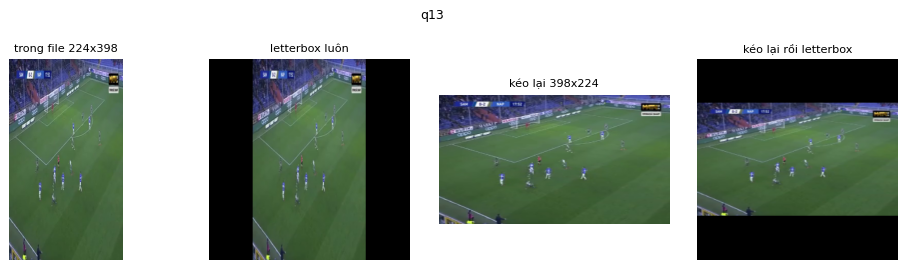

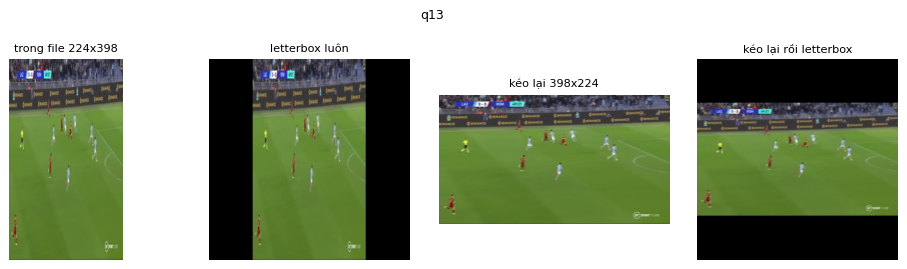

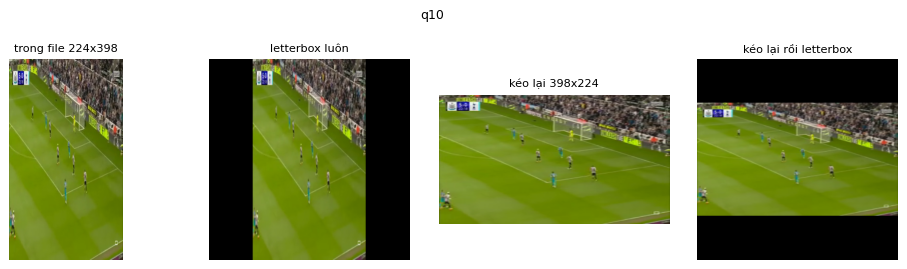

In [23]:
def read_raw(path, t=0.5):
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT) * t))
    frame = cap.read()[1]
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

tall = [s for s in clean["q13"][:3]] + [s for s in clean["q10"] if probe(s.materials[0]).height > probe(s.materials[0]).width][:1]
for s in tall:
    f = read_raw(s.materials[0])
    fixed = sample_frames(s.materials[0], 1)[0][0]
    show_frames([f, letterbox(f, 336), fixed, letterbox(fixed, 336)],
                [f"trong file {f.shape[1]}x{f.shape[0]}", "letterbox luôn", f"kéo lại {fixed.shape[1]}x{fixed.shape[0]}", "kéo lại rồi letterbox"],
                figsize=(11, 3), suptitle=s.task_id)

In [24]:
# clip doc deu tu SoccerReplay-1988
rows = []
for t in ["q10", "q11", "q13"]:
    for r in raw[t]:
        m = r["materials"][0]
        rows.append({"task": t, "nguồn": "SoccerReplay-1988" if "SoccerReplay-1988" in m else "khác"})
src = pd.DataFrame(rows)
src["hướng"] = video[video.task.isin(["q10", "q11", "q13"])]["hướng"].values
src.groupby(["nguồn", "hướng"]).size().unstack(fill_value=0)

hướng,dọc,ngang
nguồn,,
SoccerReplay-1988,1200,0
khác,0,1500


The foul has been recorded from 3 different perspectives: Main camera center lens at 1.0x speed, Main behind the goal lens at 1.4x speed, Close-up player or field referee lens at 1.8x speed. Did this foul involve a handball?


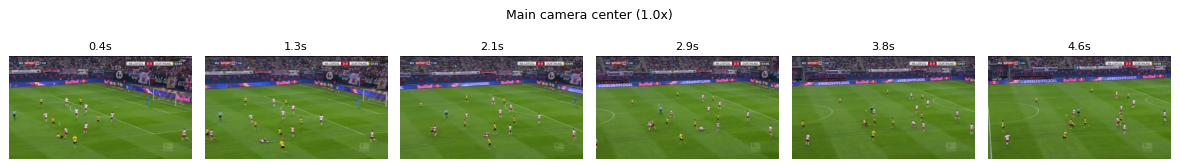

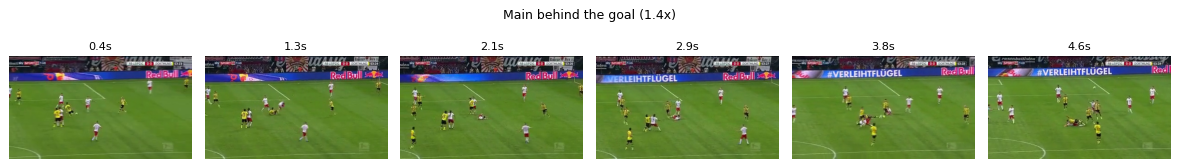

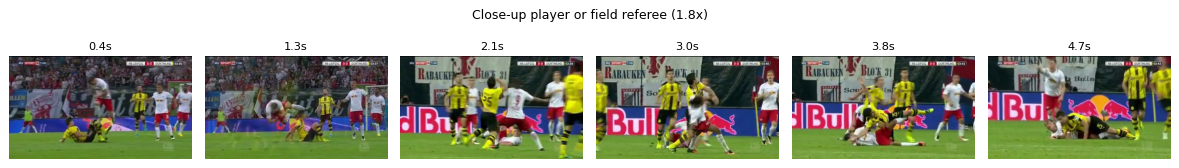

In [25]:
# q14: cac goc quay cua cung mot pha pham loi
s = clean["q14"][1]
print(s.question)
for path, view in zip(s.materials, s.meta["views"]):
    frames, ts = sample_frames(path, 6)
    show_frames(frames, [f"{t:.1f}s" for t in ts], suptitle=f"{view['camera']} ({view['speed']}x)")

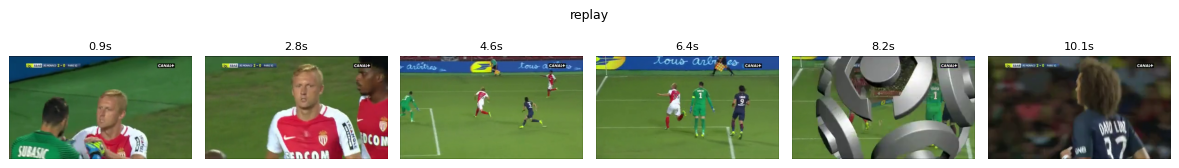

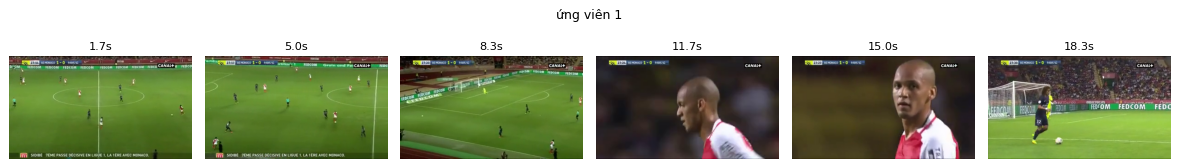

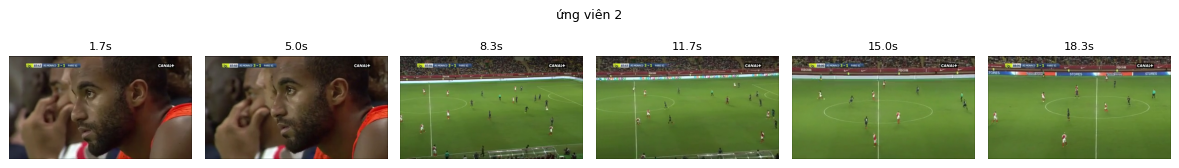

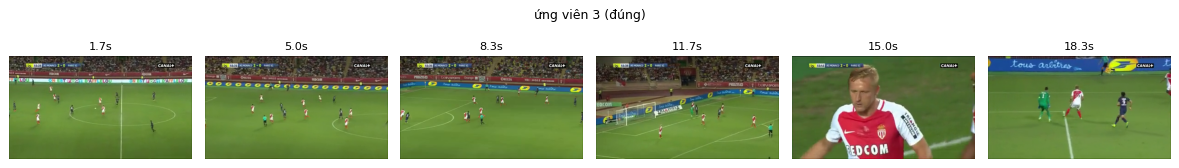

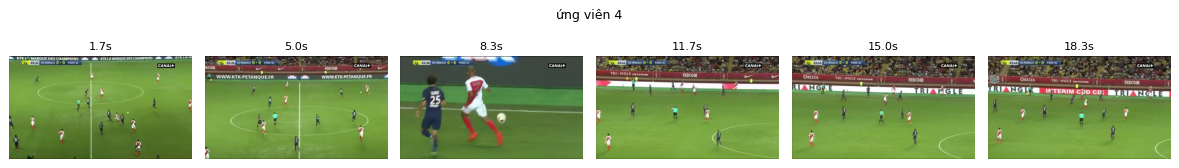

In [26]:
# q9: clip dau la replay, 4 clip sau la ung vien
s = clean["q9"][0]
names = ["replay"] + [f"ứng viên {i}" + (" (đúng)" if f"O{i}" == s.gold_key else "") for i in range(1, 5)]
for path, name in zip(s.materials, names):
    frames, ts = sample_frames(path, 6)
    show_frames(frames, [f"{t:.1f}s" for t in ts], suptitle=name)

### 4.2 Cache

In [27]:
paths = [s.materials[0] for s in clean["q8"][:30]]

with tempfile.TemporaryDirectory() as d:
    cache = PerceptionCache(Path(d) / "frames", Path(d) / "emb")
    times = []
    for _ in range(2):
        t0 = time.time()
        for p in paths:
            cache.get_frames(p, 8, 336)
        times.append(time.time() - t0)
    size = sum(f.stat().st_size for f in (Path(d) / "frames").iterdir()) / 1e6

print(f"lần 1: {times[0]:.2f}s  lần 2: {times[1]:.2f}s  (hit={cache.hits}, miss={cache.misses})")
print(f"{len(paths)} clip x 8 frame 336x336 = {size:.1f} MB")

lần 1: 5.85s  lần 2: 0.84s  (hit=30, miss=30)
30 clip x 8 frame 336x336 = 29.3 MB


In [28]:
# q14: bao nhieu lan giai ma tiet kiem duoc nho cache theo file
declared = sum(len(s.materials) for s in clean["q14"])
unique = len({m for s in clean["q14"] for m in s.materials})
print(f"{declared} lượt / {unique} file -> bớt {100 * (declared - unique) / declared:.1f}%")

634 lượt / 409 file -> bớt 35.5%


### 4.3 Embedding

In [29]:
encoder = build_encoder("clip_vit_l")
cache = PerceptionCache()

s = clean["q9"][0]
embs = [cache.get_embedding(p, 8, 336, encoder) for p in s.materials]
print(embs[0].shape, embs[0].dtype, "| norm:", np.linalg.norm(embs[0].astype(np.float32), axis=1).round(3))

(8, 768) float16 | norm: [1. 1. 1. 1. 1. 1. 1. 1.]
